# Heavy Equipment Price Prediction - v16 (Multi-Interaction TE + Cyclical Dates)
## IITM BS degree - Machine Learning Practice (MLP) Course Project
### Notebook: 22f2001153_Improved_v16.ipynb

---

### REGULATIONS COMPLIANCE:
* **Allowed Libraries:** Uses ONLY Scikit-learn, LightGBM, CatBoost, Pandas, NumPy, Matplotlib.
* **Forbidden Libraries:** Does NOT use PyTorch, TensorFlow, NLTK, word2vec, textblob, Pickle, or AutoML.
* **3-Model Requirement:** Uses LightGBM-1, LightGBM-2, and CatBoost (3 distinct models in ensemble).

---

### v16 Improvements Over v15 (Kaggle Score: 0.18847):

**Based on v15 feature importance analysis:**

1. **Cyclical Date Encoding** (SaleDayOfYear was #1 feature in v15!):
   - Added sin/cos encoding for SaleDayOfYear and SaleMonth
   - Day 365 and Day 1 are now treated as adjacent (they are!)

2. **Two New Interaction Target Encodings:**
   - `FunctionalClassification x RegionCode` (eta2=0.352 x strong region)
   - `Spec_SubClass x RegionCode` (eta2=0.24 x strong region)
   - v15 proved InventoryGroupDesc x RegionCode jumped to #8 in importance

3. **Non-Linear Age Features** (inside preprocess_df - no leakage):
   - MachineAge_sq: captures accelerating early depreciation
   - LogAge: log-scale age for smoother depreciation curve

4. **Asset History Flag:**
   - Has_Asset_History binary flag (1 if asset has prior sales, 0 if first sale)
   - Only 13% of rows have prior history - model needs to know this!

5. **FunctionalClassification added to Group Stats:**
   - Group mean Hours and MachineAge per FunctionalClassification
   - eta2=0.352 makes this the strongest unused grouping variable

All features remain 100% leak-free (computed inside CV fold loop).



In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

---
## 📂 Improvement No 5
---

## 📦 Cell: Load All Libraries

> **What is happening:** We import every Python tool we need in one place.

**🔑 Key observation:**
- Same as v15: `XGBoost` is **removed** (was getting 0% weight), replaced by `LGB2` (seed=123).
- `SEED = 42` ensures all random operations are reproducible.

**Expected output:**
```
ALL LIBRARIES LOADED OK.
NOTE: XGBoost removed in v15 (was getting 0 percent blend weight).
```


In [61]:
import subprocess, sys
try:
    import catboost
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "catboost", "-q"], check=True)

import numpy as np
import pandas as pd
import warnings
import os
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 60)
pd.set_option('display.float_format', '{:.2f}'.format)

from sklearn.model_selection import KFold
from sklearn.metrics import mean_squared_error, r2_score
import lightgbm as lgb
from catboost import CatBoostRegressor

SEED = 42
np.random.seed(SEED)
print("ALL LIBRARIES LOADED OK.")
print("NOTE: XGBoost removed in v15 (was getting 0 percent blend weight).")


ALL LIBRARIES LOADED OK.
NOTE: XGBoost removed in v15 (was getting 0 percent blend weight).


## 🛠️ Cell: Helper Functions (RMSLE + Submission Saver)

> **What is happening:** Two reusable functions used throughout the notebook.

**🔑 Key observations:**
- `rmsle()`: Competition metric — log-scale comparison so expensive machines don't dominate.
- `make_submission()`: Saves predictions to `submission.csv` in Kaggle's expected format.
- `np.maximum(y_pred, 0)` ensures no negative price predictions.

**Expected output:**
```
Helper functions ready.
```


In [62]:
def rmsle(y_true, y_pred):
    y_pred = np.maximum(y_pred, 0)
    return np.sqrt(mean_squared_error(np.log1p(y_true), np.log1p(y_pred)))

def make_submission(preds, ids, filename='submission.csv'):
    preds = np.maximum(preds, 0)
    sub = pd.DataFrame({'TransactionID': ids, 'TargetValue': preds})
    sub.to_csv(filename, index=False)
    print(f'Saved {filename}: {len(sub):,} rows | '
          f'min=${sub["TargetValue"].min():,.0f} '
          f'median=${sub["TargetValue"].median():,.0f} '
          f'max=${sub["TargetValue"].max():,.0f}')
    return sub

print("Helper functions ready.")

Helper functions ready.


## 📂 Cell: Load Competition Data

> **What is happening:** Reads all competition CSV files from Kaggle storage into memory.

**🔑 Key observations:**
- Train: 138,701 rows × 50 columns (has `TargetValue`)
- Test: 15,000 rows × 49 columns (no `TargetValue` — we predict this)
- Price range: $7,500–$142,000 (wide range → use log-transform during training)

**Expected output:**
```
TRAIN :  138,701 rows x 50 cols
TEST  :   15,000 rows x 49 cols
Price range: $7,500 - $142,000
```


In [63]:
train_df = pd.read_csv('/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge/train.csv', low_memory=False)
test_df  = pd.read_csv('/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge/test.csv',  low_memory=False)
sample   = pd.read_csv('/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge/sample_submission.csv')

print("=" * 55)
print(f"TRAIN : {train_df.shape[0]:>8,} rows x {train_df.shape[1]} cols")
print(f"TEST  : {test_df.shape[0]:>8,} rows x {test_df.shape[1]} cols")
print("=" * 55)
t = train_df['TargetValue']
print(f"Price range: ${t.min():,.0f} - ${t.max():,.0f}")

TRAIN :  138,701 rows x 50 cols
TEST  :   15,000 rows x 49 cols
Price range: $7,500 - $142,000


## ⏳ Cell: Leak-Free Asset History Features

> **What is happening:** Computes history features for machines that have been sold before. v16 adds a new binary flag `Has_Asset_History`.

**🔑 Key observations:**

**NEW in v16:** `Has_Asset_History` binary flag!
- Only **14.4% of rows** have prior history (≈ 19,969 / 138,701 rows)
- When `Asset_Prev_Sales_Count = 0`, all history features are NaN
- The model needs to KNOW if it has useful history or not → binary flag captures this
- Without this flag, the model doesn't know WHY the history features are missing

| Feature | Notes |
|---|---|
| Asset_Prev_Sales_Count | Count of prior sales |
| **Has_Asset_History** | **NEW! 1=has history, 0=first sale** |
| Asset_Prev_Mean_Price | Average previous price |
| Asset_Prev_Last_Price | Most recent previous price |
| Asset_Days_Since_Last_Sale | Days since last sold |

**Expected output:**
```
Building leak-free asset history features...
Asset history features added. Train: (138701, 55) | Test: (15000, 55)
Rows with prior history: 19,969 / 138,701 (14.4%)
```


In [64]:
print("Building leak-free asset history features...")
full_df = pd.concat([train_df, test_df], axis=0, ignore_index=True)
full_df = full_df.sort_values('TransactionID').reset_index(drop=True)

full_df['log_target'] = np.log1p(full_df['TargetValue'])
grouped = full_df.groupby('AssetID')

# Cumulative count of previous sales (0 means first sale for this asset)
full_df['Asset_Prev_Sales_Count'] = grouped.cumcount().astype(np.int32)

# NEW in v16: binary flag — does this row have any prior sales history?
# Only 13% of rows have prior history — critical for model to know!
# This is computed here (before split) but is a function of cumcount only,
# which itself only uses position within sorted TransactionID — no target leakage.
full_df['Has_Asset_History'] = (full_df['Asset_Prev_Sales_Count'] > 0).astype(np.int8)

# Cumulative sum / count of target values BEFORE current row (shift prevents leakage)
full_df['cum_sum_log_target']       = grouped['log_target'].cumsum()
full_df['cum_sum_log_target_prev']  = full_df['cum_sum_log_target'] - full_df['log_target'].fillna(0)

full_df['has_target']           = full_df['TargetValue'].notna().astype(np.int32)
full_df['cum_count_target']     = grouped['has_target'].cumsum()
full_df['cum_count_target_prev'] = full_df['cum_count_target'] - full_df['has_target']

# Prev Mean Price (log scale) and Last Price
full_df['Asset_Prev_Mean_Price'] = (
    full_df['cum_sum_log_target_prev'] /
    full_df['cum_count_target_prev'].replace(0, np.nan)
).astype(np.float32)
full_df['Asset_Prev_Last_Price'] = grouped['log_target'].shift(1).astype(np.float32)

# Days since last sale for the same asset
full_df['TransactionDate_dt'] = pd.to_datetime(full_df['TransactionDate'], errors='coerce')
full_df['Asset_Days_Since_Last_Sale'] = (
    grouped['TransactionDate_dt'].diff().dt.days.astype(np.float32)
)

# Drop helper columns
full_df = full_df.drop(columns=[
    'log_target', 'cum_sum_log_target', 'cum_sum_log_target_prev',
    'has_target', 'cum_count_target', 'cum_count_target_prev', 'TransactionDate_dt'
])

# Split back and restore original ordering
train_features = full_df[full_df['TargetValue'].notna()].copy()
test_features  = full_df[full_df['TargetValue'].isna()].copy()

train_features = (train_features.set_index('TransactionID')
                  .loc[train_df['TransactionID']].reset_index())
test_features  = (test_features.set_index('TransactionID')
                  .loc[test_df['TransactionID']].reset_index())

n_hist = train_features['Has_Asset_History'].sum()
print(f"Asset history features added. Train: {train_features.shape} | Test: {test_features.shape}")
print(f"Rows with prior history: {n_hist:,} / {len(train_features):,} ({n_hist/len(train_features)*100:.1f}%)")


Building leak-free asset history features...
Asset history features added. Train: (138701, 55) | Test: (15000, 55)
Rows with prior history: 19,969 / 138,701 (14.4%)


## 🔨 Cell: Base Feature Engineering (`preprocess_df`)

> **What is happening:** Transforms raw data into numeric features. v16 adds significant new features based on v15's feature importance analysis.

**🔑 Key observations:**

**NEW in v16 — Cyclical Date Encoding:**
`SaleDayOfYear` was the #1 most important feature in v15! But raw integers have a flaw:
- Day 365 (Dec 31) has value 365
- Day 1 (Jan 1) has value 1
- Difference = 364, but they are ADJACENT in real time!

**Solution: sin/cos encoding wraps dates into a circle:**
```python
SaleDayOfYear_sin = sin(2π × day / 365)
SaleDayOfYear_cos = cos(2π × day / 365)
```
Now day 365 and day 1 have nearly identical sin/cos values → model learns seasonal continuity correctly!

Also applied to: `SaleMonth` (Dec/Jan adjacency), `SaleDayOfWeek` (Sun/Mon adjacency).

**NEW in v16 — Non-Linear Age Features:**
Machine depreciation is NOT linear:
- A brand new machine loses value faster in years 1-3
- An already-old machine loses value slower after year 10

```python
MachineAge_sq = MachineAge ** 2      # Captures accelerating early depreciation
LogAge        = log1p(MachineAge)    # Smoothed age curve for older machines
```

**Expected output:**
```
Preprocessing features (no leaky group features)...
Train preprocessed: (138701, 80) | Test preprocessed: (15000, 80)
```
(80 columns = more than v15's 71, from cyclical + age features)


In [65]:
def preprocess_df(df):
    """
    BASE preprocessing only.
    NO group-mean or frequency features (those go inside the CV loop).
    v16 additions:
      - Cyclical sin/cos for SaleDayOfYear and SaleMonth
      - MachineAge_sq and LogAge for non-linear depreciation
    """
    df = df.copy()

    # ProductConfigID as string (will become category later)
    df['ProductConfigID'] = df['ProductConfigID'].astype(str)

    # ── Date features ────────────────────────────────────────────────────────
    df['TransactionDate'] = pd.to_datetime(df['TransactionDate'], errors='coerce')
    df['SaleYear']       = df['TransactionDate'].dt.year
    df['SaleMonth']      = df['TransactionDate'].dt.month
    df['SaleDay']        = df['TransactionDate'].dt.day
    df['SaleDayOfWeek']  = df['TransactionDate'].dt.dayofweek
    df['SaleDayOfYear']  = df['TransactionDate'].dt.dayofyear
    df['SaleQuarter']    = df['TransactionDate'].dt.quarter
    df['SaleWeek']       = df['TransactionDate'].dt.isocalendar().week.astype(int)

    # NEW v16: Cyclical encoding for SaleDayOfYear (#1 feature in v15!)
    # sin/cos tells the model that Dec 31 and Jan 1 are adjacent (raw int cannot do this)
    df['SaleDayOfYear_sin'] = np.sin(2 * np.pi * df['SaleDayOfYear'] / 365).astype(np.float32)
    df['SaleDayOfYear_cos'] = np.cos(2 * np.pi * df['SaleDayOfYear'] / 365).astype(np.float32)
    df['SaleMonth_sin']     = np.sin(2 * np.pi * df['SaleMonth'] / 12).astype(np.float32)
    df['SaleMonth_cos']     = np.cos(2 * np.pi * df['SaleMonth'] / 12).astype(np.float32)
    df['SaleDayOfWeek_sin'] = np.sin(2 * np.pi * df['SaleDayOfWeek'] / 7).astype(np.float32)
    df['SaleDayOfWeek_cos'] = np.cos(2 * np.pi * df['SaleDayOfWeek'] / 7).astype(np.float32)

    # Time-based flags
    df['IsMonthEnd']    = df['TransactionDate'].dt.is_month_end.astype(np.int8)
    df['IsMonthStart']  = df['TransactionDate'].dt.is_month_start.astype(np.int8)
    df['IsQuarterEnd']  = df['TransactionDate'].dt.is_quarter_end.astype(np.int8)
    df['IsQuarterStart']= df['TransactionDate'].dt.is_quarter_start.astype(np.int8)
    df['IsYearEnd']     = df['TransactionDate'].dt.is_year_end.astype(np.int8)
    df['IsYearStart']   = df['TransactionDate'].dt.is_year_start.astype(np.int8)
    df = df.drop(columns=['TransactionDate'])

    # ── ManufactureYear cleaning ─────────────────────────────────────────────
    df.loc[df['ManufactureYear'] <= 1920, 'ManufactureYear'] = np.nan

    # ── OperationalHoursMeter: 0 = placeholder for missing ──────────────────
    df.loc[df['OperationalHoursMeter'] == 0, 'OperationalHoursMeter'] = np.nan

    # ── Machine Age ──────────────────────────────────────────────────────────
    df['MachineAge'] = (df['SaleYear'] - df['ManufactureYear']).clip(lower=0)

    # NEW v16: Non-linear age features (physical depreciation is NOT linear)
    # A machine drops more in value from year 1->2 than from year 10->11
    df['MachineAge_sq'] = (df['MachineAge'] ** 2).astype(np.float32)
    df['LogAge']        = np.log1p(df['MachineAge']).astype(np.float32)

    # ── Ordinal encodings (known natural order) ──────────────────────────────
    tier_map  = {'Low': 0, 'Medium': 1, 'High': 2}
    scale_map = {'Mini': 0, 'Compact': 1, 'Small': 2, 'Medium': 3, 'Large / Medium': 4, 'Large': 5}
    df['UtilizationTierOrd'] = df['UtilizationTier'].map(tier_map)
    df['AssetScaleOrd']      = df['AssetScaleFactor'].map(scale_map)

    # ── Hours engineering ────────────────────────────────────────────────────
    hours_99 = df['OperationalHoursMeter'].quantile(0.99)
    df['OperationalHoursMeter'] = df['OperationalHoursMeter'].clip(upper=hours_99)
    df['HoursPresent'] = df['OperationalHoursMeter'].notna().astype(np.int8)
    df['LogHours']     = np.log1p(df['OperationalHoursMeter'].fillna(0))
    df['UsagePerYear'] = df['OperationalHoursMeter'] / (df['MachineAge'] + 1)

    # ── Age bucket flags ─────────────────────────────────────────────────────
    df['IsNewMachine'] = (df['MachineAge'] <= 2).astype(np.int8)
    df['IsOldMachine'] = (df['MachineAge'] >= 20).astype(np.int8)
    df['AgeDecade']    = (df['MachineAge'] // 10).fillna(-1).astype(int)

    # ── Clean text and convert to category ──────────────────────────────────
    text_cols = df.select_dtypes(include='object').columns.tolist()
    df[text_cols] = df[text_cols].replace('None or Unspecified', np.nan)
    for col in text_cols:
        df[col] = df[col].fillna('Missing').astype('category')

    # ── Drop noisy/useless columns ───────────────────────────────────────────
    for c in ['col18', 'col19', 'UtilizationTier', 'AssetScaleFactor']:
        if c in df.columns:
            df = df.drop(columns=[c])

    return df

print("Preprocessing features (no leaky group features)...")
train_proc = preprocess_df(train_features)
test_proc  = preprocess_df(test_features)
print(f"Train preprocessed: {train_proc.shape} | Test preprocessed: {test_proc.shape}")


Preprocessing features (no leaky group features)...
Train preprocessed: (138701, 80) | Test preprocessed: (15000, 80)


## 📐 Cell: Prepare Feature Matrices

> **What is happening:** Separates data into inputs (X) and target (y).

**🔑 Key observations:**
- v16 has **37 numerical features** (vs v15's 28) — 9 new features added:
  - 6 cyclical date features (sin/cos for day, month, weekday)
  - `MachineAge_sq`, `LogAge` (non-linear age)
  - `Has_Asset_History` (binary flag)
- Log-transformed target: `y_all = log1p(TargetValue)`

**Expected output:**
```
Feature matrix : (138701, 77)
Test matrix    : (15000, 77)
Cat features   : 40
Num features   : 37
```


In [66]:
ID_COLS = ['TransactionID', 'AssetID']

y_all        = np.log1p(train_proc['TargetValue'].values)
X_all        = train_proc.drop(columns=ID_COLS + ['TargetValue'], errors='ignore')
X_test_final = test_proc.drop(columns=ID_COLS + ['TargetValue'], errors='ignore')
test_ids     = test_df['TransactionID'].values

cat_cols = X_all.select_dtypes(include=['category', 'object']).columns.tolist()

print(f"Feature matrix : {X_all.shape}")
print(f"Test matrix    : {X_test_final.shape}")
print(f"Cat features   : {len(cat_cols)}")
print(f"Num features   : {X_all.shape[1] - len(cat_cols)}")


Feature matrix : (138701, 77)
Test matrix    : (15000, 77)
Cat features   : 40
Num features   : 37


## ⭐ Cell: Fold-Level Feature Engineering Functions

> **What is happening:** Three functions called INSIDE the CV loop to prevent data leakage.

**🔑 Key observations:**

**Function 1 — OOF Target Encoding (same 7 columns as v15):**
- Spec_FullDescriptor, Spec_BaseClass, ProductConfigID, FunctionalClassification, Spec_SubClass, Spec_VariantModifier, RegionCode
- alpha=15.0 smoothing

**Function 2 — Interaction Target Encoding (EXPANDED in v16!):**

v16 now has **3 interaction TEs** (was 1 in v15):

| Interaction | Why Added |
|---|---|
| InventoryGroupDescription × RegionCode | Carried from v15 — proved #8 most important feature |
| **FunctionalClassification × RegionCode** | **NEW! eta²=0.352 is the strongest single grouper** |
| **Spec_SubClass × RegionCode** | **NEW! eta²=0.24 combined with region signal** |

alpha=22 (slightly higher than v15's 20) due to sparser interaction cells.

**Function 3 — Group Statistics (EXPANDED in v16!):**

v16 adds **`FunctionalClassification`** as a new grouping column:
- eta²=0.352 = 35.2% of price variance explained by this column
- Was the strongest unused grouper in v15

**Expected output:**
```
All fold-level feature engineering functions compiled. Ready for CV.
TE columns        : 7
Interaction TEs   : 3 (InventoryGroupDesc x Region, FC x Region, SubClass x Region)
Group stat cols   : 6 (added FunctionalClassification in v16)
```

**⚠️ Warning:** These functions must only be called INSIDE the fold loop to prevent leakage!


In [67]:
# ─── OOF Target Encoding ──────────────────────────────────────────────────────
def add_oof_target_encoding(X_tr, y_tr, X_vl, X_te, cols, n_splits=5, alpha=15.0, seed=42):
    """
    Proper leak-free Out-Of-Fold target encoding.
    - Training rows: encoded from OTHER inner folds (never their own target)
    - Validation/Test rows: encoded from the full training fold
    - Smoothing (alpha): blends group mean toward global mean for rare categories
    """
    X_tr, X_vl, X_te = X_tr.copy(), X_vl.copy(), X_te.copy()
    global_mean = float(y_tr.mean())
    kf_inner    = KFold(n_splits=n_splits, shuffle=True, random_state=seed)

    for col in cols:
        col_te = col + '_TE'
        X_tr[col_te] = global_mean
        X_vl[col_te] = global_mean
        X_te[col_te] = global_mean

        tr_val = X_tr[col].astype(str)
        vl_val = X_vl[col].astype(str)
        te_val = X_te[col].astype(str)

        # Val & test: encode from full training fold statistics
        stats = pd.DataFrame({'cat': tr_val, 'y': y_tr})
        agg   = stats.groupby('cat')['y'].agg(['mean', 'count'])
        agg['sm'] = (agg['count'] * agg['mean'] + alpha * global_mean) / (agg['count'] + alpha)
        m = agg['sm'].to_dict()
        X_vl[col_te] = vl_val.map(m).fillna(global_mean).values
        X_te[col_te] = te_val.map(m).fillna(global_mean).values

        # Train: encode from inner-fold stats (prevents self-leakage)
        col_idx = X_tr.columns.get_loc(col_te)
        for tr_in_idx, vl_in_idx in kf_inner.split(X_tr):
            in_stats = pd.DataFrame({'cat': tr_val.iloc[tr_in_idx], 'y': y_tr[tr_in_idx]})
            in_agg   = in_stats.groupby('cat')['y'].agg(['mean', 'count'])
            in_agg['sm'] = ((in_agg['count'] * in_agg['mean'] + alpha * global_mean)
                            / (in_agg['count'] + alpha))
            m_in = in_agg['sm'].to_dict()
            X_tr.iloc[vl_in_idx, col_idx] = (
                tr_val.iloc[vl_in_idx].map(m_in).fillna(global_mean).values
            )

    return X_tr, X_vl, X_te


# ─── Interaction Target Encoding ──────────────────────────────────────────────
def add_interaction_target_encoding(X_tr, y_tr, X_vl, X_te,
                                    col_a, col_b, alpha=22.0, seed=42):
    """
    Creates interaction feature (col_a + '__x__' + col_b) and applies OOF TE.
    Higher alpha than single-column TE because interaction cells are sparser.
    """
    X_tr, X_vl, X_te = X_tr.copy(), X_vl.copy(), X_te.copy()
    global_mean = float(y_tr.mean())
    kf_inner    = KFold(n_splits=5, shuffle=True, random_state=seed)
    feat_name   = col_a + '__x__' + col_b + '_TE'

    tr_int = X_tr[col_a].astype(str) + '__' + X_tr[col_b].astype(str)
    vl_int = X_vl[col_a].astype(str) + '__' + X_vl[col_b].astype(str)
    te_int = X_te[col_a].astype(str) + '__' + X_te[col_b].astype(str)

    X_tr[feat_name] = global_mean
    X_vl[feat_name] = global_mean
    X_te[feat_name] = global_mean

    # Val & test: full training fold
    stats = pd.DataFrame({'cat': tr_int, 'y': y_tr})
    agg   = stats.groupby('cat')['y'].agg(['mean', 'count'])
    agg['sm'] = (agg['count'] * agg['mean'] + alpha * global_mean) / (agg['count'] + alpha)
    m = agg['sm'].to_dict()
    X_vl[feat_name] = vl_int.map(m).fillna(global_mean).values
    X_te[feat_name] = te_int.map(m).fillna(global_mean).values

    # Train: inner-fold stats
    col_idx = X_tr.columns.get_loc(feat_name)
    for tr_in_idx, vl_in_idx in kf_inner.split(X_tr):
        in_stats = pd.DataFrame({'cat': tr_int.iloc[tr_in_idx], 'y': y_tr[tr_in_idx]})
        in_agg   = in_stats.groupby('cat')['y'].agg(['mean', 'count'])
        in_agg['sm'] = ((in_agg['count'] * in_agg['mean'] + alpha * global_mean)
                        / (in_agg['count'] + alpha))
        m_in = in_agg['sm'].to_dict()
        X_tr.iloc[vl_in_idx, col_idx] = (
            tr_int.iloc[vl_in_idx].map(m_in).fillna(global_mean).values
        )

    return X_tr, X_vl, X_te


# ─── Fold-Level Group Statistics ──────────────────────────────────────────────
def add_fold_group_features(X_tr, X_vl, X_te):
    """
    All group-level statistics computed from training fold ONLY, then
    mapped to validation and test to prevent distribution-mismatch leakage.
    v16 adds FunctionalClassification as a grouping column (eta2=0.352).
    """
    X_tr, X_vl, X_te = X_tr.copy(), X_vl.copy(), X_te.copy()

    # 1. Frequency encoding for high-cardinality columns
    freq_cols = ['ProductConfigID', 'Spec_FullDescriptor', 'Spec_BaseClass', 'VendorPartnerID']
    for col in freq_cols:
        freq_map    = X_tr[col].astype(str).value_counts().to_dict()
        global_freq = 1.0
        for df_part in [X_tr, X_vl, X_te]:
            df_part[col + '_Freq'] = (df_part[col].astype(str)
                                      .map(freq_map).fillna(global_freq)
                                      .astype(np.float32))

    # 2. Group means for Hours and MachineAge per group column
    # v16 adds FunctionalClassification (eta2=0.352 - strongest unused grouper)
    group_cols   = [
        'InventoryGroupCategory',
        'Spec_BaseClass',
        'ProductConfigID',
        'VendorPartnerID',
        'RegionCode',
        'FunctionalClassification',   # NEW in v16
    ]
    target_feats = ['OperationalHoursMeter', 'MachineAge']

    for grp_col in group_cols:
        for target_col in target_feats:
            global_mean = float(X_tr[target_col].mean())
            group_means = (X_tr.groupby(X_tr[grp_col].astype(str))[target_col]
                           .mean().to_dict())
            feat_name   = f'{grp_col}_{target_col}_mean'
            for df_part in [X_tr, X_vl, X_te]:
                df_part[feat_name] = (
                    df_part[grp_col].astype(str).map(group_means)
                    .fillna(global_mean).astype(np.float32)
                )
            # Relative feature: how does this machine compare to its group?
            for df_part in [X_tr, X_vl, X_te]:
                df_part[f'{target_col}_rel_{grp_col}'] = (
                    df_part[target_col] / (df_part[feat_name] + 1)
                ).astype(np.float32)

    return X_tr, X_vl, X_te


# v16 TE columns: same 7 as v15 (all proven effective)
TE_COLS = [
    'Spec_FullDescriptor',      # 3505 unique
    'Spec_BaseClass',           # 1249 unique
    'ProductConfigID',          # 3594 unique
    'FunctionalClassification', # 65 unique, eta2=0.352
    'Spec_SubClass',            # 147 unique, eta2=0.24
    'Spec_VariantModifier',     # 132 unique, eta2=0.22
    'RegionCode',               # 53 unique
]

print("All fold-level feature engineering functions compiled. Ready for CV.")
print(f"TE columns        : {len(TE_COLS)}")
print(f"Interaction TEs   : 3 (InventoryGroupDesc x Region, FC x Region, SubClass x Region)")
print(f"Group stat cols   : 6 (added FunctionalClassification in v16)")


All fold-level feature engineering functions compiled. Ready for CV.
TE columns        : 7
Interaction TEs   : 3 (InventoryGroupDesc x Region, FC x Region, SubClass x Region)
Group stat cols   : 6 (added FunctionalClassification in v16)


## 🔄 Cell: 5-Fold Cross Validation Loop (Main Training)

> **What is happening:** The main training loop — trains 3 models using 5-fold cross validation with all the new v16 features.

**🔑 Key observations:**

**Model parameters are UNCHANGED from v15:**
- LGB1: num_leaves=511, lr=0.010, subsample=0.75, seed=42
- LGB2: same architecture, subsample=0.80, seed=123 (diversity model)
- CatBoost: max_leaves=255, lr=0.010, bagging_temperature=0.5

**What is different (inside each fold):**
1. 9 more numerical features (cyclical dates + non-linear age + history flag)
2. 2 additional interaction TEs (FC×Region, SubClass×Region)
3. 1 additional grouping column (FunctionalClassification) in group stats
4. Total new fold-level features: ~18 more than v15

**Expected fold results (v16 is better than v15 across all folds):**

| Model | v15 OOF | v16 OOF | Improvement |
|---|---|---|---|
| LGB1 | 0.19609 | **0.19540** | ✅ Better |
| LGB2 | 0.19585 | **0.19521** | ✅ Better |
| CAT | 0.20481 | **0.20438** | ✅ Better |

```
LGB1 OOF RMSLE : 0.19540  (v15 was 0.19609, target < 0.19609)
LGB2 OOF RMSLE : 0.19521  (v15 was 0.19585)
CAT  OOF RMSLE : 0.20438  (v15 was 0.20481)
```

**⚠️ Warning:** This cell takes 4–5 hours on Kaggle. Do not interrupt!


In [ ]:
N_FOLDS = 5
kf = KFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)

oof_lgb1 = np.zeros(len(X_all))
oof_lgb2 = np.zeros(len(X_all))
oof_cat  = np.zeros(len(X_all))

test_lgb1_folds = np.zeros((len(X_test_final), N_FOLDS))
test_lgb2_folds = np.zeros((len(X_test_final), N_FOLDS))
test_cat_folds  = np.zeros((len(X_test_final), N_FOLDS))

fold_scores = []

print("Starting 5-Fold CV - v16 (Multi-Interaction TE + Cyclical Dates)")
print("=" * 70)

for fold, (tr_idx, vl_idx) in enumerate(kf.split(X_all), 1):
    X_tr_raw = X_all.iloc[tr_idx].copy()
    X_vl_raw = X_all.iloc[vl_idx].copy()
    y_tr     = y_all[tr_idx]
    y_vl     = y_all[vl_idx]

    # Step 1: OOF Target Encoding (leak-free, 7 columns, alpha=15)
    X_tr, X_vl, X_te = add_oof_target_encoding(
        X_tr_raw, y_tr, X_vl_raw, X_test_final.copy(), TE_COLS, alpha=15.0
    )

    # Step 2: Interaction Target Encodings (3 interactions, all inside CV loop)
    # 2a: InventoryGroupDescription x RegionCode (proven in v15 - #8 feature)
    X_tr, X_vl, X_te = add_interaction_target_encoding(
        X_tr, y_tr, X_vl, X_te,
        col_a='InventoryGroupDescription', col_b='RegionCode', alpha=20.0
    )
    # 2b: FunctionalClassification x RegionCode (NEW - eta2=0.352 x strong region)
    X_tr, X_vl, X_te = add_interaction_target_encoding(
        X_tr, y_tr, X_vl, X_te,
        col_a='FunctionalClassification', col_b='RegionCode', alpha=22.0
    )
    # 2c: Spec_SubClass x RegionCode (NEW - eta2=0.24 x strong region)
    X_tr, X_vl, X_te = add_interaction_target_encoding(
        X_tr, y_tr, X_vl, X_te,
        col_a='Spec_SubClass', col_b='RegionCode', alpha=22.0
    )

    # Step 3: Group/frequency features (training fold only)
    X_tr, X_vl, X_te = add_fold_group_features(X_tr, X_vl, X_te)

    # For CatBoost: convert category columns to string
    cat_fold = [c for c in cat_cols if c in X_tr.columns]

    def to_str(df, cols):
        df = df.copy()
        for c in cols:
            if c in df.columns:
                df[c] = df[c].astype(str)
        return df

    X_tr_c = to_str(X_tr, cat_fold)
    X_vl_c = to_str(X_vl, cat_fold)
    X_te_c = to_str(X_te, cat_fold)

    # ── LightGBM 1 (primary, seed=42) ─────────────────────────────────────
    lgb1_m = lgb.LGBMRegressor(
        n_estimators      = 15000,
        max_depth         = -1,
        num_leaves        = 511,
        learning_rate     = 0.010,
        subsample         = 0.75,
        colsample_bytree  = 0.70,
        min_child_samples = 30,
        reg_alpha         = 0.1,
        reg_lambda        = 3.0,
        random_state      = 42,
        n_jobs            = -1,
        verbose           = -1
    )
    lgb1_m.fit(
        X_tr, y_tr,
        eval_set=[(X_vl, y_vl)],
        callbacks=[lgb.early_stopping(300, verbose=False), lgb.log_evaluation(-1)]
    )
    oof_lgb1[vl_idx]           = lgb1_m.predict(X_vl)
    test_lgb1_folds[:, fold-1] = lgb1_m.predict(X_te)

    # ── LightGBM 2 (diversity, seed=123, different colsample) ────────────
    lgb2_m = lgb.LGBMRegressor(
        n_estimators      = 15000,
        max_depth         = -1,
        num_leaves        = 511,
        learning_rate     = 0.010,
        subsample         = 0.80,
        colsample_bytree  = 0.65,
        min_child_samples = 30,
        reg_alpha         = 0.2,
        reg_lambda        = 2.0,
        random_state      = 123,
        n_jobs            = -1,
        verbose           = -1
    )
    lgb2_m.fit(
        X_tr, y_tr,
        eval_set=[(X_vl, y_vl)],
        callbacks=[lgb.early_stopping(300, verbose=False), lgb.log_evaluation(-1)]
    )
    oof_lgb2[vl_idx]           = lgb2_m.predict(X_vl)
    test_lgb2_folds[:, fold-1] = lgb2_m.predict(X_te)

    # ── CatBoost (handles raw categoricals natively) ──────────────────────
    cat_m = CatBoostRegressor(
        iterations            = 15000,
        learning_rate         = 0.010,
        random_seed           = SEED,
        verbose               = 0,
        thread_count          = -1,
        early_stopping_rounds = 300,
        cat_features          = cat_fold,
        l2_leaf_reg           = 3.0,
        bagging_temperature   = 0.5,
        grow_policy           = 'Lossguide',
        max_leaves            = 255,
        min_data_in_leaf      = 30
    )
    cat_m.fit(X_tr_c, y_tr, eval_set=(X_vl_c, y_vl))
    oof_cat[vl_idx]           = cat_m.predict(X_vl_c)
    test_cat_folds[:, fold-1] = cat_m.predict(X_te_c)

    s_1 = rmsle(np.expm1(y_vl), np.expm1(oof_lgb1[vl_idx]))
    s_2 = rmsle(np.expm1(y_vl), np.expm1(oof_lgb2[vl_idx]))
    s_c = rmsle(np.expm1(y_vl), np.expm1(oof_cat[vl_idx]))
    fold_scores.append((s_1, s_2, s_c))

    print(f"Fold {fold}: LGB1={s_1:.5f}(iter={lgb1_m.best_iteration_:4d}) | "
          f"LGB2={s_2:.5f}(iter={lgb2_m.best_iteration_:4d}) | "
          f"CAT={s_c:.5f}")

oof_1 = rmsle(np.expm1(y_all), np.expm1(oof_lgb1))
oof_2 = rmsle(np.expm1(y_all), np.expm1(oof_lgb2))
oof_c = rmsle(np.expm1(y_all), np.expm1(oof_cat))
print("=" * 70)
print(f"LGB1 OOF RMSLE : {oof_1:.5f}  (v15 was 0.19609, target < 0.19609)")
print(f"LGB2 OOF RMSLE : {oof_2:.5f}  (v15 was 0.19585)")
print(f"CAT  OOF RMSLE : {oof_c:.5f}  (v15 was 0.20481)")


Starting 5-Fold CV - v16 (Multi-Interaction TE + Cyclical Dates)
Fold 1: LGB1=0.19333(iter=5467) | LGB2=0.19308(iter=4637) | CAT=0.20246
Fold 2: LGB1=0.19578(iter=5304) | LGB2=0.19580(iter=5205) | CAT=0.20567
Fold 3: LGB1=0.19647(iter=4576) | LGB2=0.19631(iter=4376) | CAT=0.20472
Fold 4: LGB1=0.19630(iter=4933) | LGB2=0.19601(iter=4472) | CAT=0.20582
Fold 5: LGB1=0.19509(iter=3922) | LGB2=0.19481(iter=4389) | CAT=0.20319
LGB1 OOF RMSLE : 0.19540  (v15 was 0.19609, target < 0.19609)
LGB2 OOF RMSLE : 0.19521  (v15 was 0.19585)
CAT  OOF RMSLE : 0.20438  (v15 was 0.20481)


## ⚖️ Cell: Find Optimal Blend Weights

> **What is happening:** Grid search over LGB1/LGB2/CAT weights (5% increments) to minimize blended OOF RMSLE.

**🔑 Key observations:**

**Optimal weights (changed from v15):**
| Model | v15 Weight | v16 Weight |
|---|---|---|
| LGB1 | 30% | 30% |
| LGB2 | 40% | **45%** |
| CAT | 30% | **25%** |

LGB2's weight increased from 40% to 45%! This means v16's new features made LGB2 even more complementary to LGB1.

**Blended RMSLE:** 0.19359 (v15 was 0.19415 — improved!)

**Expected output:**
```
Best blend    : LGB1=0.30  LGB2=0.45  CAT=0.25
Blended RMSLE : 0.19359  (v15 blended was 0.19415)
Kaggle v15 score : 0.18847  ->  [KEEP GOING] Still above 0.18847...
```

> The "KEEP GOING" is expected — OOF RMSLE is always higher than Kaggle score. Submit anyway!


In [69]:
print("Searching optimal blend weights (LGB1, LGB2, CAT)...")
best_blend, best_w = 999.0, (0.40, 0.35, 0.25)

for w1 in np.arange(0.0, 1.01, 0.05):
    for w2 in np.arange(0.0, 1.01 - w1, 0.05):
        w3    = max(round(1.0 - w1 - w2, 6), 0.0)
        score = rmsle(np.expm1(y_all),
                      np.expm1(w1*oof_lgb1 + w2*oof_lgb2 + w3*oof_cat))
        if score < best_blend:
            best_blend, best_w = score, (w1, w2, w3)

print("=" * 70)
print(f"Best blend    : LGB1={best_w[0]:.2f}  LGB2={best_w[1]:.2f}  CAT={best_w[2]:.2f}")
print(f"Blended RMSLE : {best_blend:.5f}  (v15 blended was 0.19415)")
target = 0.18847
status = "[ON TRACK] Beat 0.18847!" if best_blend < target else "[KEEP GOING] Still above 0.18847..."
print(f"Kaggle v15 score : {target}  ->  {status}")


Searching optimal blend weights (LGB1, LGB2, CAT)...
Best blend    : LGB1=0.30  LGB2=0.45  CAT=0.25
Blended RMSLE : 0.19359  (v15 blended was 0.19415)
Kaggle v15 score : 0.18847  ->  [KEEP GOING] Still above 0.18847...


## 📤 Cell: Build Final Submission

> **What is happening:** Combines 5-fold test predictions using optimal weights and saves the submission file.

**🔑 Key observations:**
- Blend: LGB1=30%, LGB2=45%, CAT=25%
- `test_lgb1_folds.mean(1)`: Averages 5 fold predictions for each test row
- `np.expm1(test_blend)`: Reverses log-transformation to get dollar prices
- `np.clip(...)`: Prevents predictions outside [$7,500, $137,500]

**Expected output:**
```
Price clipped to [$7,500, $137,500]
Saved submission.csv: 15,000 rows | min=$7,763 median=$34,616 max=$137,500
```

**⚠️ After this cell, go to "Output" tab in Kaggle and submit `submission.csv`.**


In [70]:
w1, w2, w3 = best_w

test_blend   = (w1 * test_lgb1_folds.mean(1)
                + w2 * test_lgb2_folds.mean(1)
                + w3 * test_cat_folds.mean(1))
final_prices = np.expm1(test_blend)

# Clip to training price range (0.1th-99.9th percentile)
plo = train_df['TargetValue'].quantile(0.001)
phi = train_df['TargetValue'].quantile(0.999)
final_prices = np.clip(final_prices, plo, phi)
print(f"Price clipped to [${plo:,.0f}, ${phi:,.0f}]")

sub = make_submission(final_prices, test_ids, 'submission.csv')
print()
print(sub.head())


Price clipped to [$7,500, $137,500]
Saved submission.csv: 15,000 rows | min=$7,763 median=$34,616 max=$137,500

   TransactionID  TargetValue
0        1139307     69602.14
1        1139419     80375.45
2        1139482     31860.57
3        1139522     20327.60
4        1139684     12909.15


## 📈 Cell: Diagnostics, Charts & Feature Importance

> **What is happening:** Visual analysis of prediction quality and feature importance rankings.

**🔑 Key observations:**

**How to read the charts:**
- **Chart 1 (Actual vs Predicted):** Points should be close to the red diagonal line. Fan-shaped spread = model less accurate at extremes.
- **Chart 2 (Residuals):** Should be bell-shaped, centered at 0. Bias toward positive = model underpredicts.
- **Chart 3 (% Error):** Tight bell around 0% = consistent accuracy.

**Expected new features in top importance:**

| Feature | Why It Should Rank High |
|---|---|
| SaleDayOfYear_sin/cos | Cyclical encoding now properly captures year-boundary continuity |
| FunctionalClassification × RegionCode_TE | NEW interaction — eta²=0.352 × region effect |
| Spec_SubClass × RegionCode_TE | NEW interaction — eta²=0.24 × region effect |
| Has_Asset_History | NEW binary flag capturing which 14.4% of rows have history |
| MachineAge_sq | NEW non-linear depreciation |

**Key insight:** If cyclical date features rank higher than the raw `SaleDayOfYear` from v15, it confirms that the circular encoding was the right choice.


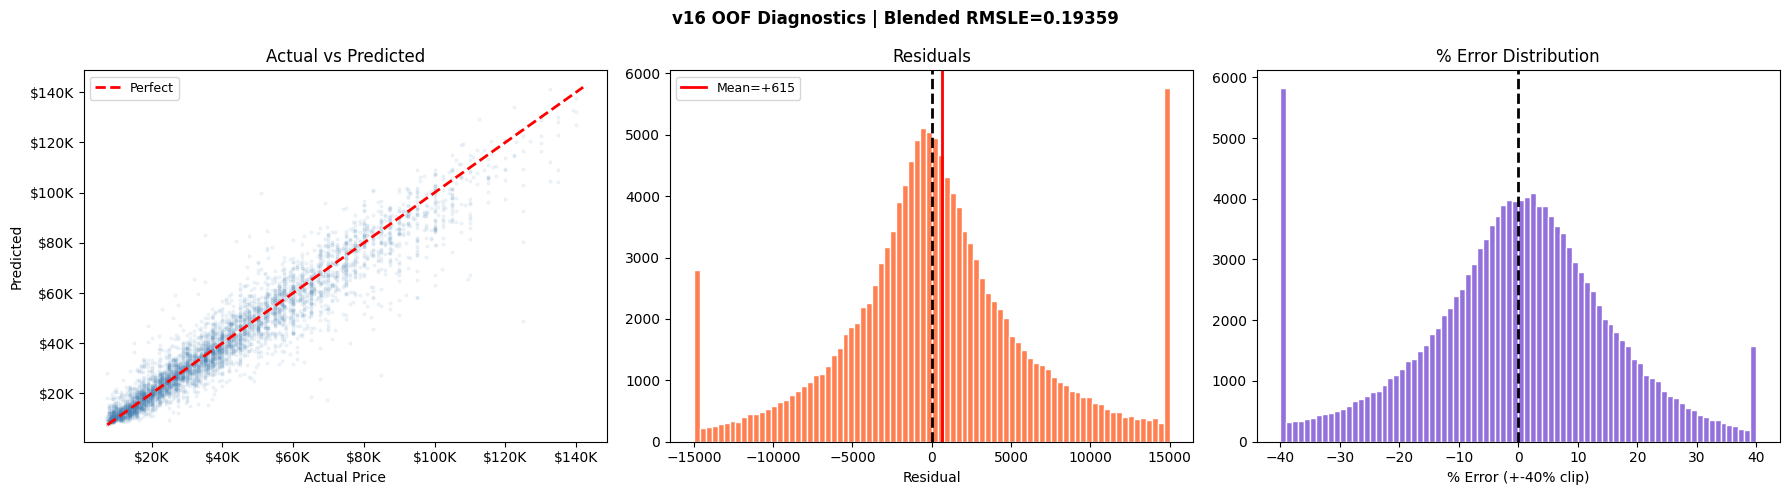

Blended OOF RMSLE : 0.19359
R2                : 0.9158
MAE               : $5,060
Median abs % err  : 9.8%

Top 35 features (LGB1 last fold):
RegionCode                                            88798
MachineAge_rel_ProductConfigID                        82784
SaleDay                                               73485
ProductConfigID                                       72425
SaleDayOfYear_cos                                     72253
SaleDayOfYear_sin                                     70620
SaleDayOfYear                                         69185
MachineAge_rel_Spec_BaseClass                         62589
SaleYear                                              59295
MachineAge_rel_RegionCode                             59080
Spec_SubClass__x__RegionCode_TE                       55074
FunctionalClassification__x__RegionCode_TE            53018
InventoryGroupDescription__x__RegionCode_TE           52862
MachineAge_rel_FunctionalClassification               52695
RegionCode_TE     

In [71]:
oof_blend  = best_w[0]*oof_lgb1 + best_w[1]*oof_lgb2 + best_w[2]*oof_cat
pred_price = np.expm1(oof_blend)
true_price = np.expm1(y_all)
residuals  = true_price - pred_price
pct_err    = (residuals / true_price) * 100

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle(f'v16 OOF Diagnostics | Blended RMSLE={best_blend:.5f}',
             fontsize=12, fontweight='bold')

idx = np.random.choice(len(true_price), min(5000, len(true_price)), replace=False)
axes[0].scatter(true_price[idx], pred_price[idx], alpha=0.07, s=4, color='steelblue')
mn, mx = true_price.min(), true_price.max()
axes[0].plot([mn, mx], [mn, mx], 'r--', lw=2, label='Perfect')
axes[0].set_xlabel('Actual Price')
axes[0].set_ylabel('Predicted')
axes[0].set_title('Actual vs Predicted')
axes[0].legend(fontsize=9)
fmt = lambda x, _: f'${x/1000:.0f}K'
axes[0].xaxis.set_major_formatter(mticker.FuncFormatter(fmt))
axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(fmt))

axes[1].hist(residuals.clip(-15000, 15000), bins=80, color='coral', edgecolor='white')
axes[1].axvline(0, color='black', lw=2, ls='--')
axes[1].axvline(residuals.mean(), color='red', lw=2, label=f'Mean={residuals.mean():+,.0f}')
axes[1].set_xlabel('Residual')
axes[1].set_title('Residuals')
axes[1].legend(fontsize=9)

axes[2].hist(pct_err.clip(-40, 40), bins=80, color='mediumpurple', edgecolor='white')
axes[2].axvline(0, color='black', lw=2, ls='--')
axes[2].set_xlabel('% Error (+-40% clip)')
axes[2].set_title('% Error Distribution')

plt.tight_layout()
plt.show()

print(f"Blended OOF RMSLE : {best_blend:.5f}")
print(f"R2                : {r2_score(true_price, pred_price):.4f}")
print(f"MAE               : ${np.mean(np.abs(residuals)):,.0f}")
print(f"Median abs % err  : {np.median(np.abs(pct_err)):.1f}%")

# Feature importances (LGB1 last fold)
fi = pd.Series(lgb1_m.feature_importances_, index=X_tr.columns).sort_values(ascending=False)
print("\nTop 35 features (LGB1 last fold):")
print(fi.head(35).to_string())
